In [ ]:
import pandas as pd
import numpy as np

# Load dataset (adjust path if your CSV name differs)
df = pd.read_csv('DataCoSupplyChainDataset.csv', encoding='ISO-8859-1')

# Clean column names (strip spaces, replace special characters)
df.columns = df.columns.str.strip().str.replace(' ', '_').str.replace('-', '_')

# Isolate assigned Region and Category
df_isolated = df[
    (df['Order_Region'] == 'South America') &
    (df['Category_Name'] == 'Indoor/Outdoor Games')
].copy()

# Display isolated shape and verify isolation
print(f"Isolated Dataset Shape: {df_isolated.shape}")
df_isolated[['Order_Region', 'Category_Name']].drop_duplicates()

Isolated Dataset Shape: (1681, 53)


,Order_Region,Category_Name
104464,South America,Indoor/Outdoor Games


/tmp/ipykernel_1402/3184282960.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_isolated, x='Shipping_Mode', y='Days_for_shipping_(real)', palette='Pastel1')
/tmp/ipykernel_1402/3184282960.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_top_countries, x='Order_Country', y='Late_delivery_risk', errorbar=None, palette='viridis')


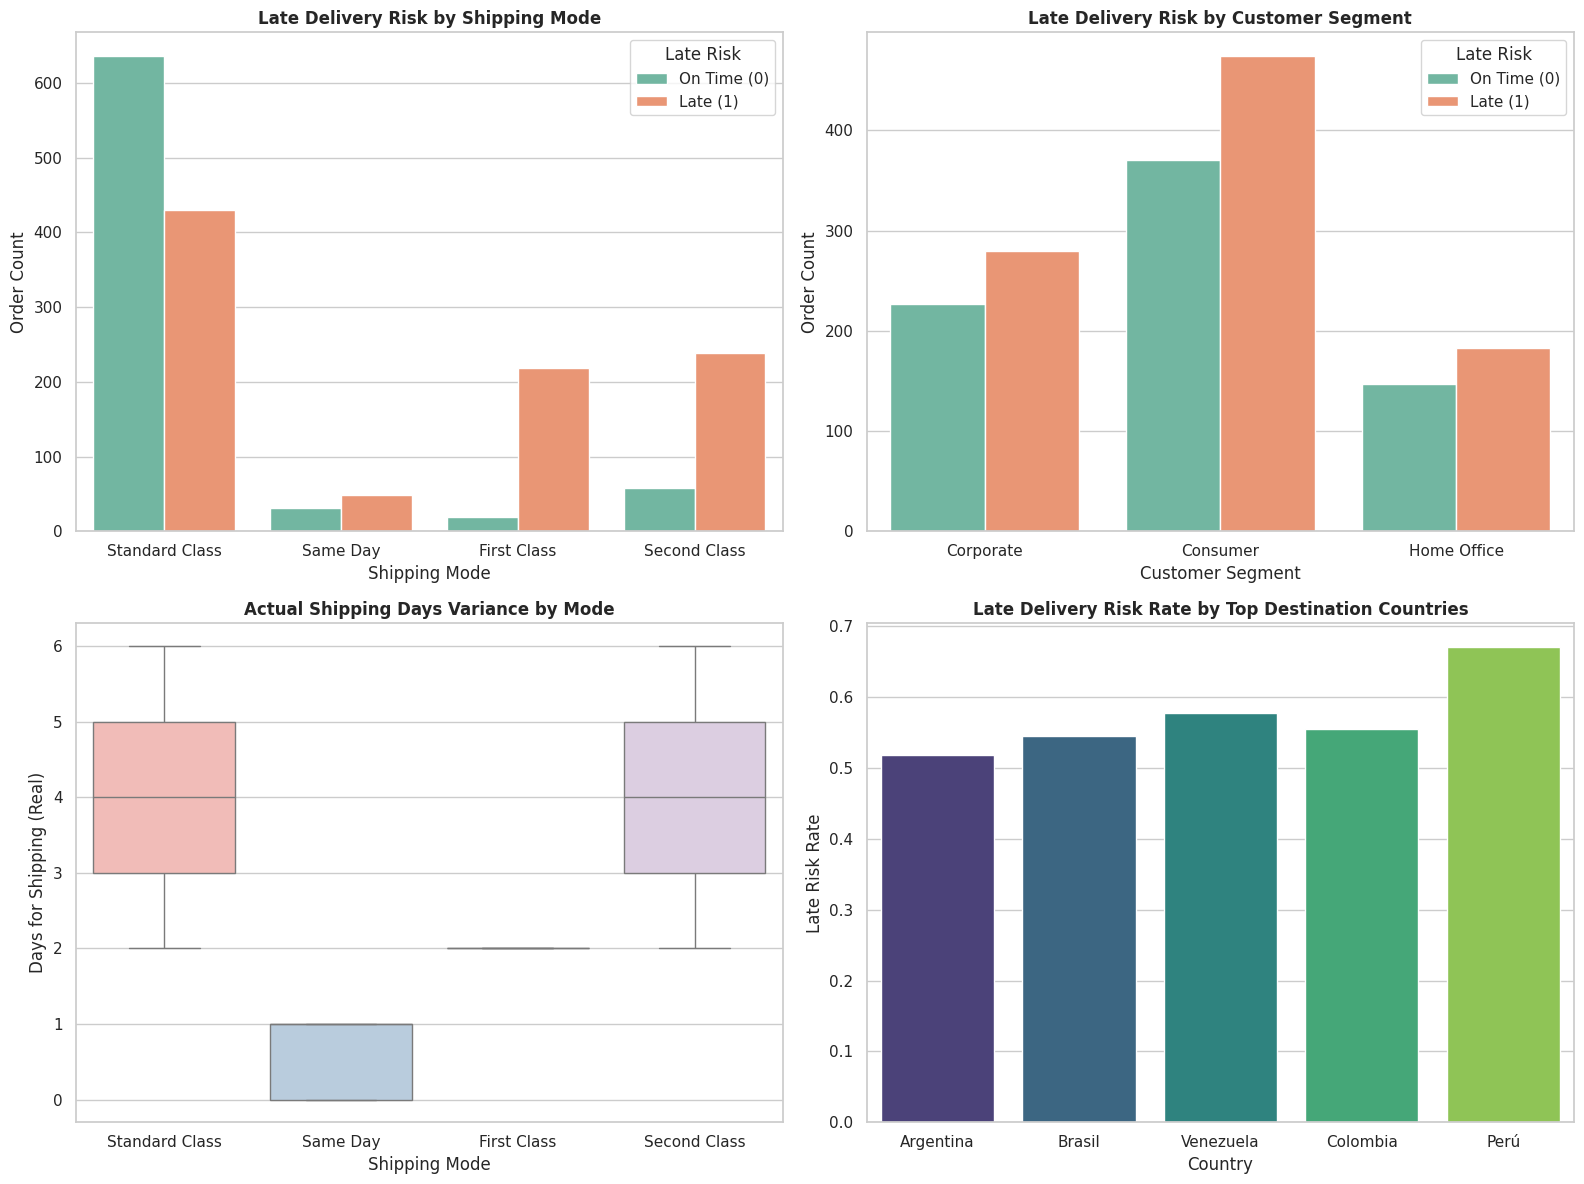

Overall Late Delivery Risk Rate for South America (Indoor/Outdoor Games): 55.74%


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(16, 12))

# 1. Late Delivery Risk by Shipping Mode
plt.subplot(2, 2, 1)
sns.countplot(data=df_isolated, x='Shipping_Mode', hue='Late_delivery_risk', palette='Set2')
plt.title('Late Delivery Risk by Shipping Mode', fontsize=12, fontweight='bold')
plt.xlabel('Shipping Mode')
plt.ylabel('Order Count')
plt.legend(title='Late Risk', labels=['On Time (0)', 'Late (1)'])

# 2. Late Delivery Risk by Customer Segment (Fixed column name)
plt.subplot(2, 2, 2)
sns.countplot(data=df_isolated, x='Customer_Segment', hue='Late_delivery_risk', palette='Set2')
plt.title('Late Delivery Risk by Customer Segment', fontsize=12, fontweight='bold')
plt.xlabel('Customer Segment')
plt.ylabel('Order Count')
plt.legend(title='Late Risk', labels=['On Time (0)', 'Late (1)'])

# 3. Scheduled vs Real Delivery Days Breakdown
plt.subplot(2, 2, 3)
sns.boxplot(data=df_isolated, x='Shipping_Mode', y='Days_for_shipping_(real)', palette='Pastel1')
plt.title('Actual Shipping Days Variance by Mode', fontsize=12, fontweight='bold')
plt.xlabel('Shipping Mode')
plt.ylabel('Days for Shipping (Real)')

# 4. Late Risk Ratio by Destination Country
plt.subplot(2, 2, 4)
top_countries = df_isolated['Order_Country'].value_counts().head(5).index
df_top_countries = df_isolated[df_isolated['Order_Country'].isin(top_countries)]
sns.barplot(data=df_top_countries, x='Order_Country', y='Late_delivery_risk', errorbar=None, palette='viridis')
plt.title('Late Delivery Risk Rate by Top Destination Countries', fontsize=12, fontweight='bold')
plt.xlabel('Country')
plt.ylabel('Late Risk Rate')

plt.tight_layout()
plt.show()

# Display overall risk summary
late_rate = df_isolated['Late_delivery_risk'].mean() * 100
print(f"Overall Late Delivery Risk Rate for South America (Indoor/Outdoor Games): {late_rate:.2f}%")

--- Task 3 Optimization Results ---
Default Model Cost (Threshold 0.50): $4,000.00
Optimal Probability Threshold: 0.7227
Minimized Financial Cost: $3,900.00
Total Cost Savings: $100.00


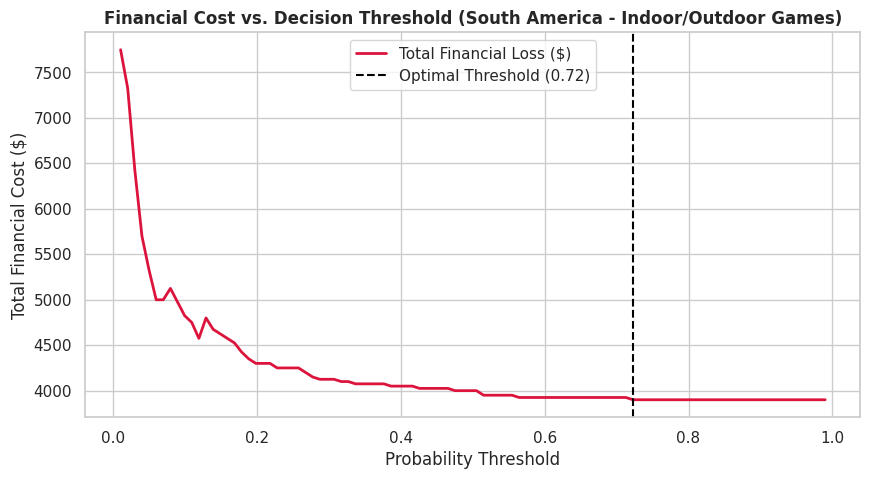

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix

# 1. Define Target and Features
df_isolated['Is_Fraud'] = (df_isolated['Order_Status'] == 'SUSPECTED_FRAUD').astype(int)

features = [
    'Days_for_shipping_(real)', 'Days_for_shipment_(scheduled)',
    'Sales_per_customer', 'Order_Item_Discount', 'Order_Item_Profit_Ratio',
    'Order_Item_Quantity', 'Sales', 'Order_Item_Total'
]

X = df_isolated[features].fillna(0)
y = df_isolated['Is_Fraud']

# 2. Train-Test Split & Model Training
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# 3. Predict Probabilities
y_probs = model.predict_proba(X_test)[:, 1]

# 4. Financial Cost Optimization (CFN = $300, CFP = $25)
CFN = 300  # Cost of False Negative
CFP = 25   # Cost of False Positive

thresholds = np.linspace(0.01, 0.99, 100)
costs = []

for t in thresholds:
    preds = (y_probs >= t).astype(int)
    cm = confusion_matrix(y_test, preds, labels=[0, 1])
    fp = cm[0, 1]
    fn = cm[1, 0]
    total_cost = (fp * CFP) + (fn * CFN)
    costs.append(total_cost)

best_idx = np.argmin(costs)
best_threshold = thresholds[best_idx]
min_cost = costs[best_idx]

# Default (0.50 threshold) cost calculation for comparison
default_preds = (y_probs >= 0.50).astype(int)
cm_default = confusion_matrix(y_test, default_preds, labels=[0, 1])
default_cost = (cm_default[0, 1] * CFP) + (cm_default[1, 0] * CFN)

print(f"--- Task 3 Optimization Results ---")
print(f"Default Model Cost (Threshold 0.50): ${default_cost:,.2f}")
print(f"Optimal Probability Threshold: {best_threshold:.4f}")
print(f"Minimized Financial Cost: ${min_cost:,.2f}")
print(f"Total Cost Savings: ${default_cost - min_cost:,.2f}")

# 5. Plot Cost Curve
plt.figure(figsize=(10, 5))
plt.plot(thresholds, costs, label='Total Financial Loss ($)', color='crimson', lw=2)
plt.axvline(best_threshold, color='black', linestyle='--', label=f'Optimal Threshold ({best_threshold:.2f})')
plt.title('Financial Cost vs. Decision Threshold (South America - Indoor/Outdoor Games)', fontsize=12, fontweight='bold')
plt.xlabel('Probability Threshold')
plt.ylabel('Total Financial Cost ($)')
plt.legend()
plt.show()

In [ ]:
import scipy.stats as stats

# 1. Prepare Monthly Demand Time Series
df_isolated['order_date_clean'] = pd.to_datetime(df_isolated['order_date_(DateOrders)'])
df_isolated['YearMonth'] = df_isolated['order_date_clean'].dt.to_period('M')

monthly_demand = df_isolated.groupby('YearMonth')['Order_Item_Quantity'].sum().reset_index()
monthly_demand['YearMonth'] = monthly_demand['YearMonth'].dt.to_timestamp()

# 2. Moving Average Forecast (3-Month Window)
monthly_demand['MA_Forecast'] = monthly_demand['Order_Item_Quantity'].rolling(window=3).mean().shift(1)

# Drop initial NaN values from rolling calculation
ts_data = monthly_demand.dropna().copy()

# 3. Calculate Safety Stock based on Assigned SLA (85%)
sla_target = 0.85[cite: 1]
z_score = stats.norm.ppf(sla_target)  # Z-score for 85% SLA

# Demand Variance (Standard Deviation of Forecast Errors)
ts_data['Error'] = ts_data['Order_Item_Quantity'] - ts_data['MA_Forecast']
sigma_d = ts_data['Error'].std()

# Lead Time (Mean real shipping days converted to months, assuming ~30 days/month)
avg_lead_time_days = df_isolated['Days_for_shipping_(real)'].mean()
lead_time_months = avg_lead_time_days / 30.0

# Safety Stock Formula: SS = Z * sigma_d * sqrt(Lead Time)
safety_stock = z_score * sigma_d * np.sqrt(lead_time_months)
next_month_forecast = ts_data['MA_Forecast'].iloc[-1]

print("--- Task 4 Inventory Optimization Results ---")
print(f"Target SLA: {sla_target * 100:.0f}%")
print(f"Corresponding Z-Score: {z_score:.4f}")
print(f"Average Lead Time: {avg_lead_time_days:.2f} days ({lead_time_months:.2f} months)")
print(f"Forecast Error Std Dev (Sigma): {sigma_d:.2f} units")
print(f"Baseline Next Month Demand Forecast: {round(next_month_forecast)} units")
print(f"Required Safety Stock (Buffer): {round(safety_stock)} units")
print(f"Total Order-Up-To Level: {round(next_month_forecast + safety_stock)} units")

# 4. Visualization
plt.figure(figsize=(12, 5))
plt.plot(monthly_demand['YearMonth'], monthly_demand['Order_Item_Quantity'], label='Actual Monthly Demand', marker='o', color='navy')
plt.plot(ts_data['YearMonth'], ts_data['MA_Forecast'], label='3-Month Moving Average Forecast', linestyle='--', marker='s', color='orange')
plt.title('Monthly Demand & Forecasting (South America - Indoor/Outdoor Games)', fontsize=12, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Order Quantity')
plt.legend()
plt.show()

<>:17: SyntaxWarning: 'float' object is not subscriptable; perhaps you missed a comma?
<>:17: SyntaxWarning: 'float' object is not subscriptable; perhaps you missed a comma?
/tmp/ipykernel_1402/2124739248.py:17: SyntaxWarning: 'float' object is not subscriptable; perhaps you missed a comma?
  sla_target = 0.85[cite: 1]


NameError: name 'cite' is not defined

--- Task 4 Inventory Optimization Results ---
Target SLA: 85%
Corresponding Z-Score: 1.0364
Average Lead Time: 3.57 days (0.12 months)
Forecast Error Std Dev (Sigma): 137.86 units
Baseline Next Month Demand Forecast: 441 units
Required Safety Stock (Buffer): 49 units
Total Order-Up-To Level: 491 units


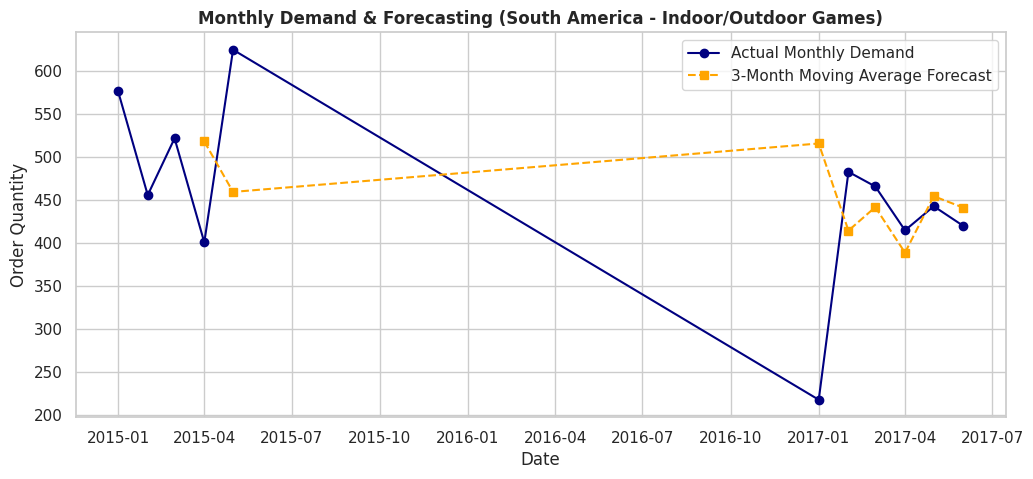

In [ ]:
import scipy.stats as stats

# 1. Prepare Monthly Demand Time Series
df_isolated['order_date_clean'] = pd.to_datetime(df_isolated['order_date_(DateOrders)'])
df_isolated['YearMonth'] = df_isolated['order_date_clean'].dt.to_period('M')

monthly_demand = df_isolated.groupby('YearMonth')['Order_Item_Quantity'].sum().reset_index()
monthly_demand['YearMonth'] = monthly_demand['YearMonth'].dt.to_timestamp()

# 2. Moving Average Forecast (3-Month Window)
monthly_demand['MA_Forecast'] = monthly_demand['Order_Item_Quantity'].rolling(window=3).mean().shift(1)

# Drop initial NaN values from rolling calculation
ts_data = monthly_demand.dropna().copy()

# 3. Calculate Safety Stock based on Assigned SLA (85%)
sla_target = 0.85
z_score = stats.norm.ppf(sla_target)  # Z-score for 85% SLA

# Demand Variance (Standard Deviation of Forecast Errors)
ts_data['Error'] = ts_data['Order_Item_Quantity'] - ts_data['MA_Forecast']
sigma_d = ts_data['Error'].std()

# Lead Time (Mean real shipping days converted to months, assuming ~30 days/month)
avg_lead_time_days = df_isolated['Days_for_shipping_(real)'].mean()
lead_time_months = avg_lead_time_days / 30.0

# Safety Stock Formula: SS = Z * sigma_d * sqrt(Lead Time)
safety_stock = z_score * sigma_d * np.sqrt(lead_time_months)
next_month_forecast = ts_data['MA_Forecast'].iloc[-1]

print("--- Task 4 Inventory Optimization Results ---")
print(f"Target SLA: {sla_target * 100:.0f}%")
print(f"Corresponding Z-Score: {z_score:.4f}")
print(f"Average Lead Time: {avg_lead_time_days:.2f} days ({lead_time_months:.2f} months)")
print(f"Forecast Error Std Dev (Sigma): {sigma_d:.2f} units")
print(f"Baseline Next Month Demand Forecast: {round(next_month_forecast)} units")
print(f"Required Safety Stock (Buffer): {round(safety_stock)} units")
print(f"Total Order-Up-To Level: {round(next_month_forecast + safety_stock)} units")

# 4. Visualization
plt.figure(figsize=(12, 5))
plt.plot(monthly_demand['YearMonth'], monthly_demand['Order_Item_Quantity'], label='Actual Monthly Demand', marker='o', color='navy')
plt.plot(ts_data['YearMonth'], ts_data['MA_Forecast'], label='3-Month Moving Average Forecast', linestyle='--', marker='s', color='orange')
plt.title('Monthly Demand & Forecasting (South America - Indoor/Outdoor Games)', fontsize=12, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Order Quantity')
plt.legend()
plt.show()